# Supplementary Figure (pooled curves): pooled out-of-fold ROC and precision-recall curves

- a, b: ROC and precision-recall curves, BRCA/CRC versus healthy;
- c, d: the same, pan-cancer versus healthy.

Four methods (Data-driven, ATAC-seq, RNA-seq, ichorCNA) on the pooled out-of-fold predictions of the nested CV (each participant scored by the one outer fold that tested it). Legends: pooled AUROC and average precision with participant-level bootstrap 95% intervals (2,000 resamples within each class). Chance: the diagonal (ROC) and the cancer prevalence (PR).

Source data: `data/<cohort>/fig3_predictions.csv` (BRCA/CRC), `data/<cohort>/fig4a_predictions.csv` (pan-cancer) and `data/<cohort>/stats_method_comparisons.csv` (from `export/export_method_comparisons.py`; supplies the AUROC intervals, and the pooled AUROCs are asserted to match it). Writes `output/<cohort>/figS_pooled_curves.*` and `figS_pooled_curves_values.csv`.

In [1]:
import os

# Data paths are relative to src/figures/; hop there if the kernel started elsewhere
if not os.path.isdir("data") and os.path.isdir(os.path.join("src", "figures", "data")):
    os.chdir(os.path.join("src", "figures"))

# --- cohort switch: "all" = the full cohort, "no_deep" = without the 30 deep-sequenced healthy (default) ---
COHORT = os.environ.get("FIG_COHORT", "no_deep")
assert COHORT in ("all", "no_deep"), COHORT
_DATA = "data" if COHORT == "all" else os.path.join("data", COHORT)
_OUT = "output" if COHORT == "all" else os.path.join("output", COHORT)
os.makedirs(_OUT, exist_ok=True)
_FALLBACKS = set()


def data_path(name):
    """Source-data path for the selected cohort (full-cohort fallback with a notice)."""
    p = os.path.join(_DATA, name)
    if COHORT != "all" and not os.path.exists(p):
        if name not in _FALLBACKS:
            print(f"   [cohort {COHORT}] {name} not exported for this cohort - using the full-cohort file")
            _FALLBACKS.add(name)
        p = os.path.join("data", name)
    return p


def out_path(name):
    """Output path for the selected cohort."""
    return os.path.join(_OUT, name)


print(f"cohort: {COHORT} (source data from {_DATA}/, figures to {_OUT}/)")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, roc_auc_score, precision_recall_curve, average_precision_score

import _figstyle as fs
fs.apply()

METHODS = {"data_driven": "Data-driven", "atac": "ATAC-seq", "rna": "RNA-seq", "ichorcna": "ichorCNA"}
BASELINE_KEY = {"atac": "ATAC", "rna": "RNA", "ichorcna": "ichorCNA"}     # baseline names in the comparison table
TASKS = {"brca_crc": ("BRCA/CRC versus healthy", "BRCA/CRC vs healthy", "fig3_predictions.csv"),
         "pancan": ("Pan-cancer versus healthy", "Pan-cancer vs healthy", "fig4a_predictions.csv")}
N_BOOT, SEED = 2000, 20261120

cohort: no_deep (source data from data\no_deep/, figures to output\no_deep/)


In [2]:
def task_scores(csv):
    """Participants of the task (data-driven rows with an outer fold) and every method's score aligned to them."""
    d = pd.read_csv(data_path(csv))
    dd = d[(d["method"] == "data_driven") & d["fold"].notna()].drop_duplicates("sample_id").set_index("sample_id")
    y = dd["y_true"].astype(int).to_numpy()
    scores = {}
    for m in METHODS:
        o = d[d["method"] == m].drop_duplicates("sample_id").set_index("sample_id").reindex(dd.index)
        assert o["score"].notna().all(), (csv, m)
        assert (o["y_true"].astype(int).to_numpy() == y).all(), (csv, m)
        scores[m] = o["score"].to_numpy(float)
    return y, scores


def boot_ap(y, s, rng):
    """Participant-level bootstrap 95% interval of the average precision, resampling within each class."""
    pos, neg = s[y == 1], s[y == 0]
    yb = np.r_[np.ones(len(pos)), np.zeros(len(neg))]
    vals = np.empty(N_BOOT)
    for i in range(N_BOOT):
        vals[i] = average_precision_score(yb, np.r_[rng.choice(pos, len(pos)), rng.choice(neg, len(neg))])
    return np.percentile(vals, [2.5, 97.5])


comp = pd.read_csv(data_path("stats_method_comparisons.csv"))
rng = np.random.default_rng(SEED)
data, rows = {}, []
for t, (title, comp_label, csv) in TASKS.items():
    y, scores = task_scores(csv)
    c = comp[comp["task"] == comp_label].set_index("baseline")
    assert len(c) == 3, comp_label
    data[t] = (y, scores)
    for m, name in METHODS.items():
        s = scores[m]
        auroc = roc_auc_score(y, s)
        if m == "data_driven":
            ref = c[["pooled_auc_dd", "pooled_auc_dd_lo", "pooled_auc_dd_hi"]].to_numpy()
            assert np.allclose(ref, ref[0]), "data-driven pooled AUROC differs between comparison rows"
            ref = ref[0]
        else:
            ref = c.loc[BASELINE_KEY[m], ["pooled_auc_base", "pooled_auc_base_lo", "pooled_auc_base_hi"]].to_numpy(float)
        assert abs(auroc - ref[0]) < 1e-9, (t, m, auroc, ref[0])
        ap = average_precision_score(y, s)
        ap_lo, ap_hi = boot_ap(y, s, rng)
        rows.append(dict(task=title, method=name, n_cancer=int(y.sum()), n_healthy=int((y == 0).sum()),
                         prevalence=y.mean(), pooled_auroc=auroc, auroc_lo=ref[1], auroc_hi=ref[2],
                         average_precision=ap, ap_lo=ap_lo, ap_hi=ap_hi))

summary = pd.DataFrame(rows)
# pinned pooled AUROCs
assert round(summary.query("task == 'BRCA/CRC versus healthy' and method == 'Data-driven'")["pooled_auroc"].item(), 3) == 0.960
assert round(summary.query("task == 'Pan-cancer versus healthy' and method == 'Data-driven'")["pooled_auroc"].item(), 3) == 0.967
summary.to_csv(out_path("figS_pooled_curves_values.csv"), index=False)
summary.round(3)

,task,method,n_cancer,n_healthy,prevalence,pooled_auroc,auroc_lo,auroc_hi,average_precision,ap_lo,ap_hi
0,BRCA/CRC versus healthy,Data-driven,80,164,0.328,0.960,0.933,0.980,0.941,0.904,0.970
1,BRCA/CRC versus healthy,ATAC-seq,80,164,0.328,0.892,0.845,0.935,0.814,0.733,0.891
2,BRCA/CRC versus healthy,RNA-seq,80,164,0.328,0.613,0.531,0.687,0.420,0.361,0.518
3,BRCA/CRC versus healthy,ichorCNA,80,164,0.328,0.672,0.592,0.745,0.605,0.518,0.689
4,Pan-cancer versus healthy,Data-driven,203,164,0.553,0.967,0.950,0.981,0.977,0.965,0.986
5,Pan-cancer versus healthy,ATAC-seq,203,164,0.553,0.884,0.846,0.917,0.894,0.856,0.930
6,Pan-cancer versus healthy,RNA-seq,203,164,0.553,0.652,0.596,0.709,0.693,0.641,0.755
7,Pan-cancer versus healthy,ichorCNA,203,164,0.553,0.675,0.621,0.728,0.763,0.720,0.803


saved output\no_deep\figS_pooled_curves.png/.pdf at 178 x 130 mm


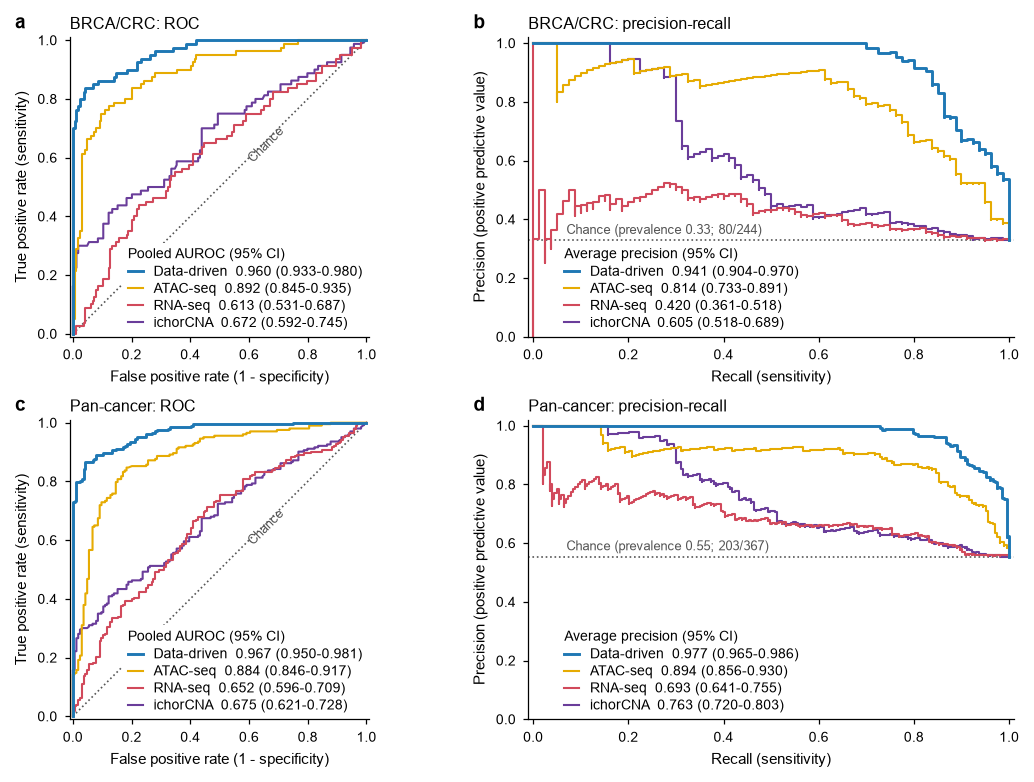

In [3]:
fig, axes = plt.subplots(2, 2, figsize=fs.size(rows=2, height=5.1), layout="constrained")
letters = iter("abcd")
order = list(METHODS)[::-1]          # draw the baselines first, the data-driven model on top
for row, (t, (title, _, _)) in enumerate(TASKS.items()):
    y, scores = data[t]
    s_t = summary[summary["task"] == title].set_index("method")
    prev = y.mean()
    short = title.split(" versus ")[0]

    # ROC
    ax = axes[row, 0]
    ax.plot([0, 1], [0, 1], ls=":", color=fs.CHANCE, lw=0.8, zorder=1)
    handles = {}
    for m in order:
        name = METHODS[m]
        fpr, tpr, _ = roc_curve(y, scores[m])
        r = s_t.loc[name]
        handles[m], = ax.plot(fpr, tpr, color=fs.METHOD[name], lw=1.4 if m == "data_driven" else 1.0,
                              zorder=3 if m == "data_driven" else 2,
                              label=f"{name}  {r.pooled_auroc:.3f} ({r.auroc_lo:.3f}-{r.auroc_hi:.3f})")
    ax.legend([handles[m] for m in METHODS], [handles[m].get_label() for m in METHODS],
              title="Pooled AUROC (95% CI)", loc="lower right", alignment="left", handlelength=1.1,
              borderaxespad=0.1, frameon=True, facecolor="white", edgecolor="none", framealpha=1.0)   # hides the diagonal
    ax.set(xlim=(-0.01, 1.01), ylim=(-0.01, 1.01), xlabel="False positive rate (1 - specificity)",
           ylabel="True positive rate (sensitivity)", aspect="equal")
    ax.text(0.62, 0.575, "Chance", rotation=45, rotation_mode="anchor", color=fs.CHANCE, fontsize=fs.VALUE,
            ha="left", va="bottom")
    fs.panel(ax, next(letters), f"{short}: ROC")

    # precision-recall
    ax = axes[row, 1]
    ax.axhline(prev, ls=":", color=fs.CHANCE, lw=0.8, zorder=1)
    handles = {}
    for m in order:
        name = METHODS[m]
        prec, rec, _ = precision_recall_curve(y, scores[m])
        r = s_t.loc[name]
        handles[m], = ax.plot(rec, prec, drawstyle="steps-post", color=fs.METHOD[name],
                              lw=1.4 if m == "data_driven" else 1.0, zorder=3 if m == "data_driven" else 2,
                              label=f"{name}  {r.average_precision:.3f} ({r.ap_lo:.3f}-{r.ap_hi:.3f})")
    ax.legend([handles[m] for m in METHODS], [handles[m].get_label() for m in METHODS],
              title="Average precision (95% CI)", loc="lower left", bbox_to_anchor=(0.06, 0.0),
              alignment="left", handlelength=1.1, borderaxespad=0.1)
    ax.text(0.07, prev + 0.012, f"Chance (prevalence {prev:.2f}; {int(y.sum())}/{len(y)})", color=fs.CHANCE,
            fontsize=fs.VALUE, ha="left", va="bottom")
    ax.set(xlim=(-0.01, 1.01), ylim=(0, 1.02), xlabel="Recall (sensitivity)", ylabel="Precision (positive predictive value)")
    fs.panel(ax, next(letters), f"{short}: precision-recall")

fs.save(fig, out_path("figS_pooled_curves"))